In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
_r = pathlib.Path.cwd().resolve()
while not (_r / "config" / "settings.yaml").exists() and _r != _r.parent:
    _r = _r.parent
sys.path.insert(0, str(_r))                      # makes `import src...` work from any folder
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from src.notebook_utils import *
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 40, "display.width", 140)
print("project root:", _r)

project root: /app


# Survey analysis - consumer perceptions of FinTech cybersecurity and trust
Instrument: `questionnaire.md` (12 five-point Likert items, 3 demographic bands, 3 behaviours). **Privacy:** pseudonymised ID, banded demographics, k-anonymity enforced, no free text.

> The bundled CSV is synthetic (latent-factor model). Replace `survey_data.csv` with real, consented responses and re-run.

In [2]:
from src.preprocessing.anonymize import k_anonymity
from src.trust_scoring.scoring import score_respondents, reliability_report, reverse_code
from src.schema import SURVEY_ITEMS
sv = load_survey(); print(sv.shape); k_anonymity(sv, CFG['trust']['k_anonymity'])

(355, 19)


{'k_required': 5,
 'min_group_size': 5,
 'groups_below_k': 0,
 'satisfied': True,
 'quasi_identifiers': ['age_band', 'education', 'usage_frequency']}

In [3]:
items = list(SURVEY_ITEMS)
desc = sv[items].agg(['mean', 'std', 'median']).T; desc['dimension'] = [SURVEY_ITEMS[q][0] for q in items]; desc['text'] = [SURVEY_ITEMS[q][1][:70] for q in items]; desc.round(2)

,mean,std,median,dimension,text
q01,3.35,1.04,3.0,perceived_security,I feel my money is safe when I use my main Fin...
q02,3.29,1.09,3.0,perceived_security,My FinTech provider uses strong security measu...
q03,3.27,1.06,3.0,perceived_security,I am confident my FinTech provider can detect ...
q04,3.32,0.94,3.0,privacy_assurance,My FinTech provider handles my personal data r...
q05,3.30,1.01,3.0,privacy_assurance,I understand how my financial data is used and...
q06,3.24,0.94,3.0,transparency,My provider clearly communicates security inci...
q07,3.33,0.94,3.0,transparency,Security and privacy settings are easy to find...
q08,3.29,0.86,3.0,reliability,The app works reliably when I make payments.
q09,3.19,0.89,3.0,reliability,My provider resolves fraud or dispute cases qu...
q10,3.34,0.97,3.0,behavioural_intent,I would recommend my FinTech provider to frien...


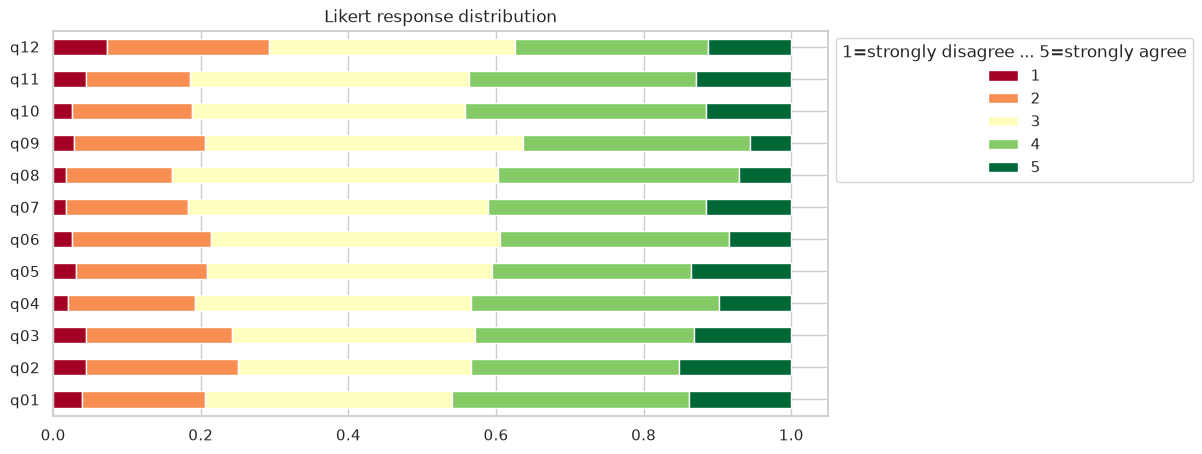

In [4]:
lik = sv[items].apply(lambda c: c.value_counts(normalize=True)).T.fillna(0).sort_index(axis=1)
lik.plot.barh(stacked=True, colormap='RdYlGn', figsize=(10, 5), title='Likert response distribution'); plt.legend(title='1=strongly disagree ... 5=strongly agree', bbox_to_anchor=(1, 1))

Text(0.5, 1.0, 'Inter-item Spearman correlation (q12 reverse-coded)')

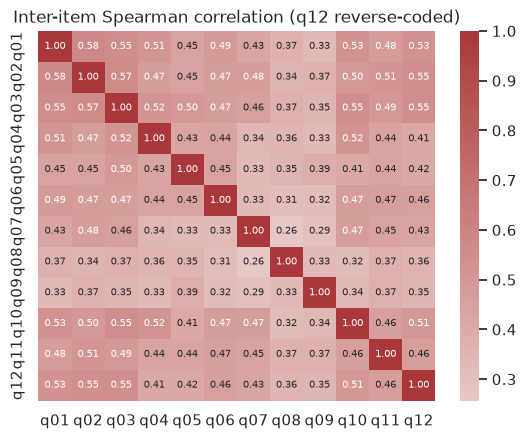

In [5]:
r = reverse_code(sv); sns.heatmap(r[items].corr(method='spearman'), cmap='vlag', center=0, annot=True, fmt='.2f', annot_kws={'size': 7}); plt.title('Inter-item Spearman correlation (q12 reverse-coded)')

In [6]:
sc = score_respondents(sv, CFG); full = sv.merge(sc[['respondent_id', 'trust_score', 'segment']], on='respondent_id')
full.groupby('uses_mfa').trust_score.agg(['count', 'mean', 'std']).round(1).join(full.groupby('experienced_fraud').trust_score.mean().round(1).rename('by_fraud_exp'), how='outer')

,count,mean,std,by_fraud_exp
uses_mfa,,,,
0,145,47.9,15.1,58.4
1,210,62.6,15.9,48.1


In [7]:
pd.crosstab(full.usage_frequency, full.segment, normalize='index').round(3)

segment,High,Low,Moderate
usage_frequency,,,
daily,0.200,0.311,0.489
monthly,0.080,0.480,0.440
weekly,0.107,0.364,0.529


In [8]:
pd.Series(reliability_report(sv)).round(3).to_frame('Cronbach alpha')

,Cronbach alpha
overall,0.906
perceived_security,0.838
privacy_assurance,0.601
transparency,0.517
reliability,0.490
behavioural_intent,0.647
